In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

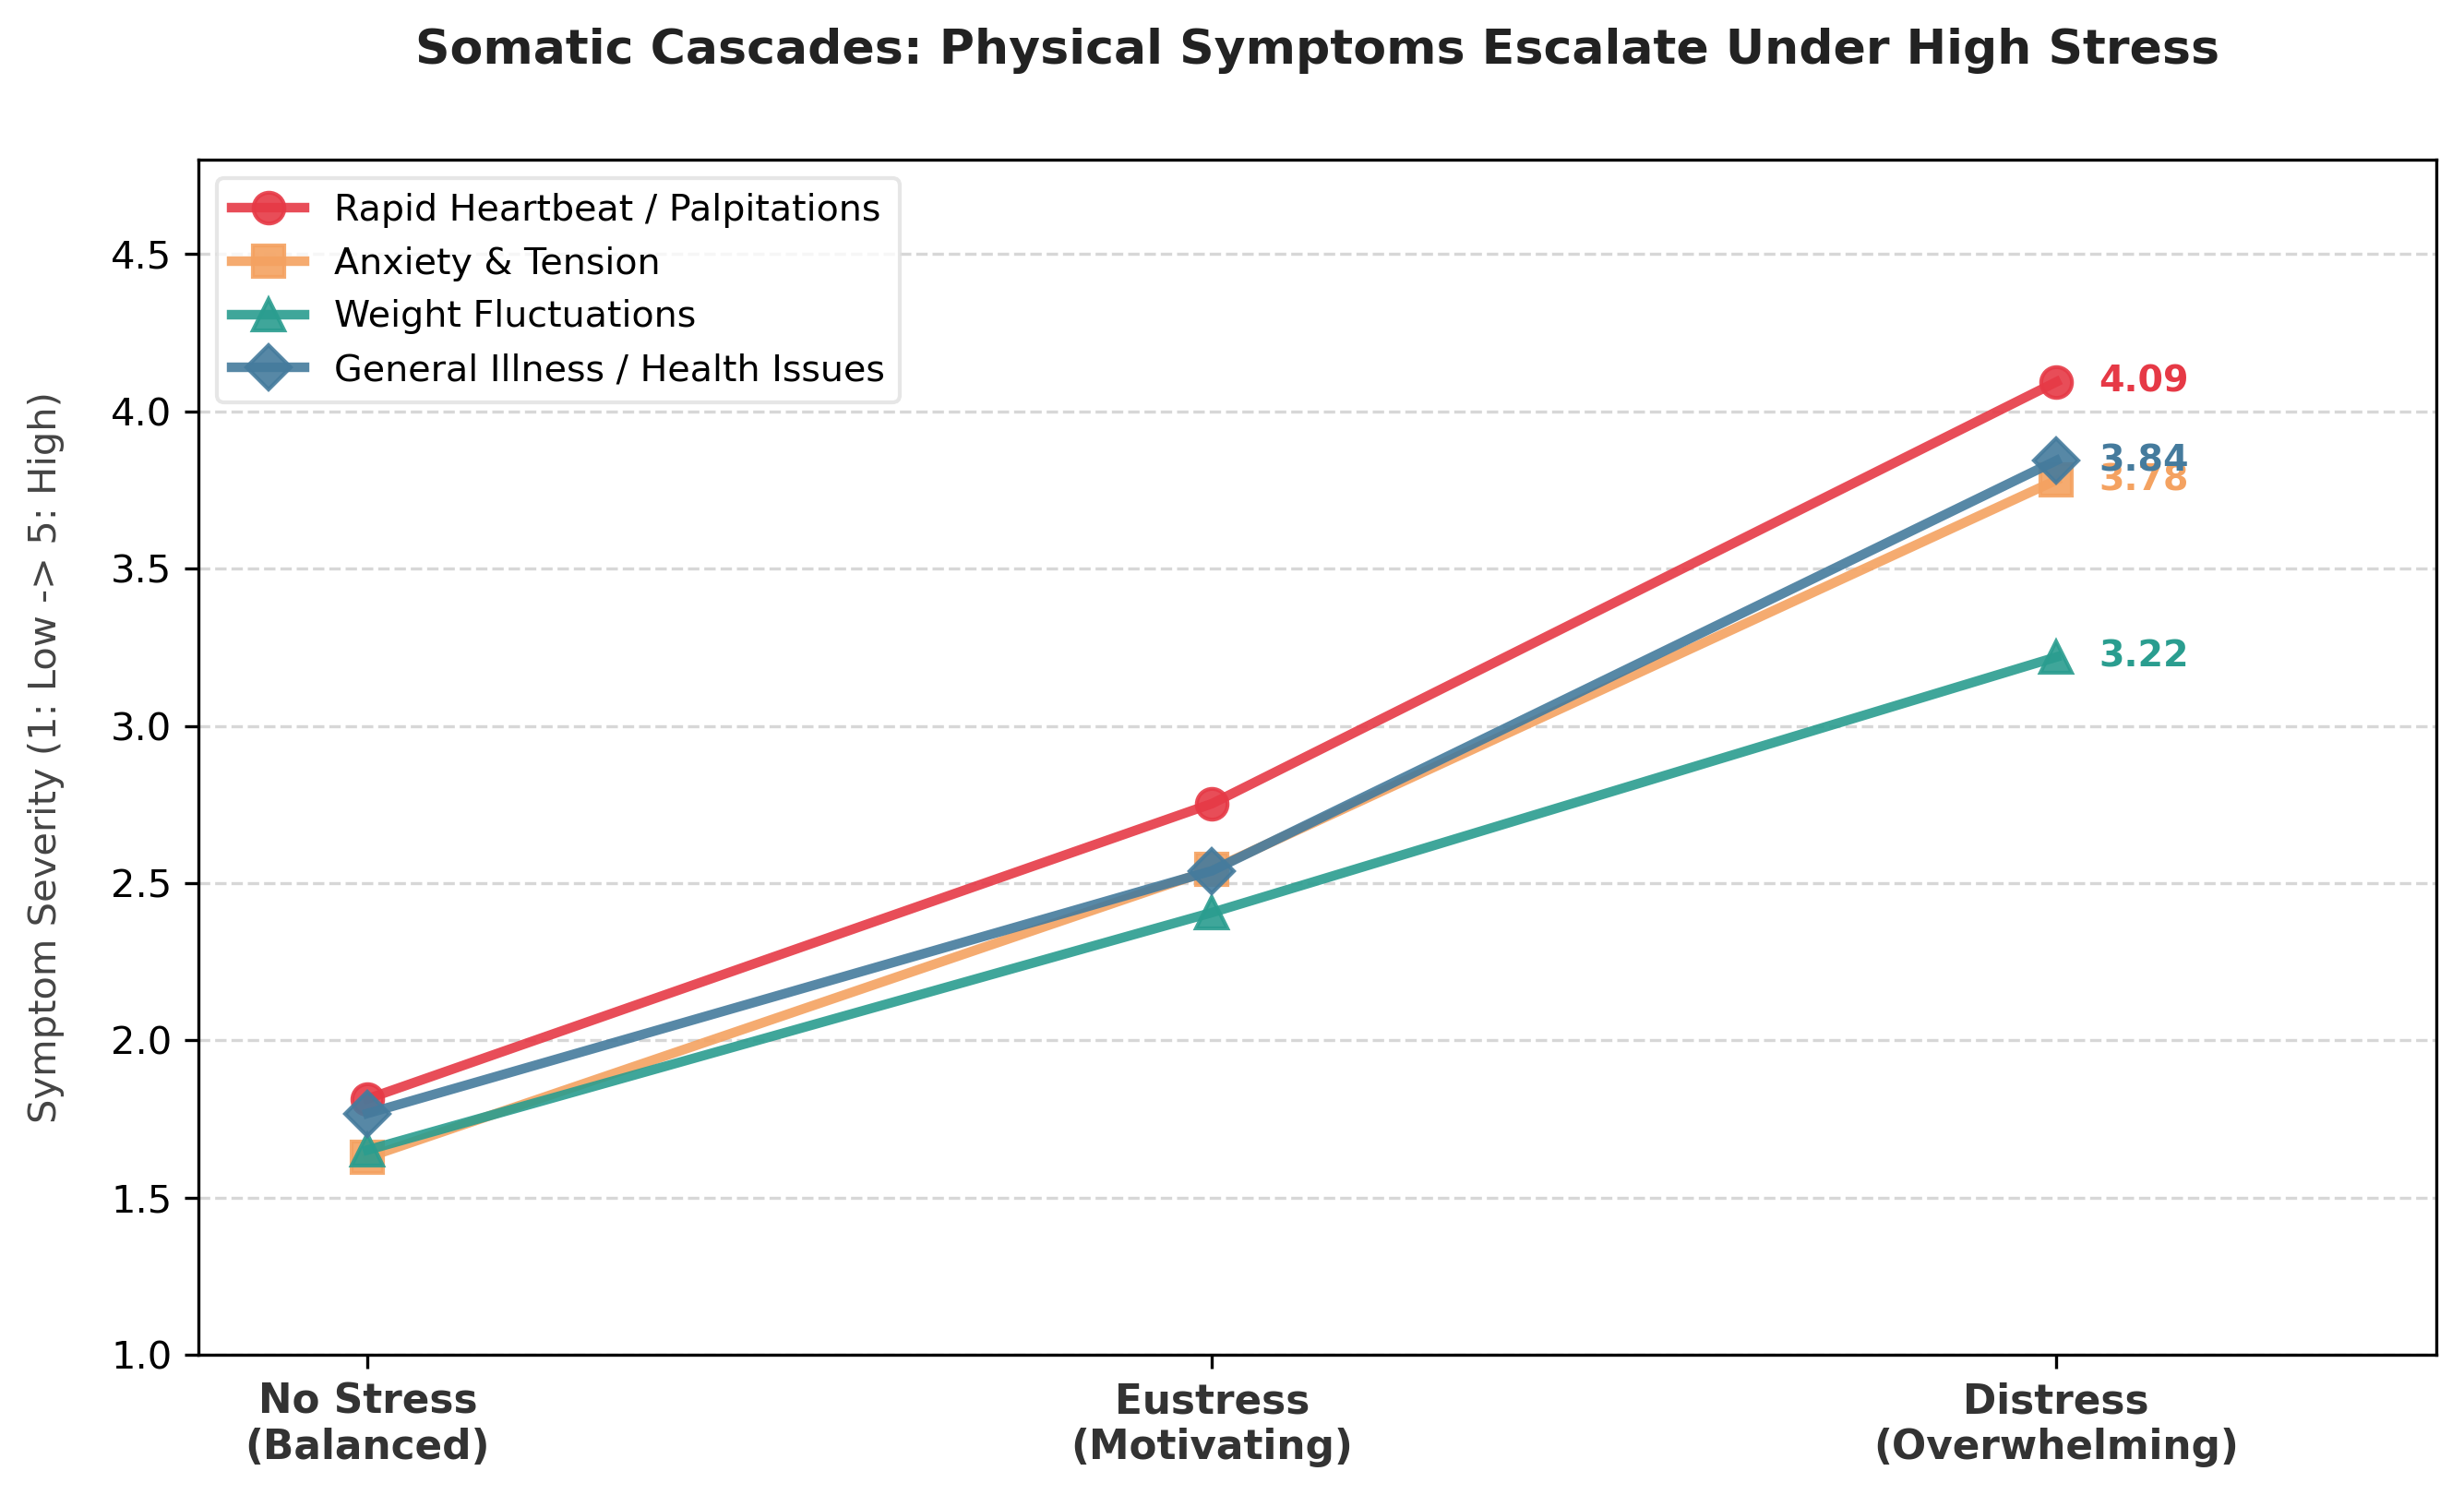

In [6]:
df = pd.read_csv('Stress_Dataset.csv')

df['Stress_Short'] = df['Which type of stress do you primarily experience?'].map({
    'Eustress (Positive Stress) - Stress that motivates and enhances performance.': 'Eustress',
    'No Stress - Currently experiencing minimal to no stress.': 'No Stress',
    'Distress (Negative Stress) - Stress that causes anxiety and impairs well-being.': 'Distress'
})

physio_cols = [
    'Have you noticed a rapid heartbeat or palpitations?',
    'Have you been dealing with anxiety or tension recently?',
    'Have you gained/lost weight?',
    'Have you been experiencing any illness or health issues?'
]

physio_labels = [
    'Rapid Heartbeat / Palpitations',
    'Anxiety & Tension',
    'Weight Fluctuations',
    'General Illness / Health Issues'
]

physio_df = df.groupby('Stress_Short')[physio_cols].mean().reindex(['No Stress', 'Eustress', 'Distress'])

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=300)

x_coords = [0, 1, 2]
colors_metrics = ['#E63946', '#F4A261', '#2A9D8F', '#457B9D']
markers = ['o', 's', '^', 'D']

for idx, col in enumerate(physio_cols):
    y_values = physio_df[col].values
    ax.plot(x_coords, y_values, label=physio_labels[idx], color=colors_metrics[idx], 
            marker=markers[idx], markersize=8, linewidth=2.5, alpha=0.9)
    
    ax.text(2 + 0.05, y_values[2], f"{y_values[2]:.2f}", va='center', ha='left', 
            fontsize=9.5, fontweight='bold', color=colors_metrics[idx])

ax.set_xticks(x_coords)
ax.set_xticklabels(['No Stress\n(Balanced)', 'Eustress\n(Motivating)', 'Distress\n(Overwhelming)'], 
                   fontsize=10.5, fontweight='bold', color='#333333')

ax.set_ylabel('Symptom Severity (1: Low -> 5: High)', fontsize=10, labelpad=12, color='#444444')
ax.set_ylim(1.0, 4.8)
ax.set_xlim(-0.2, 2.45)

ax.yaxis.grid(True, linestyle='--', alpha=0.5)
ax.xaxis.grid(False)

ax.set_title('Somatic Cascades: Physical Symptoms Escalate Under High Stress', fontsize=12.5, fontweight='bold', pad=25, color='#222222')
ax.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='#E0E0E0', fontsize=9.5)

plt.tight_layout()
plt.show()